# IEI097 – MINERÍA DE DATOS
## Unidad II – Actividad 2.10
### Laboratorio de Clustering: K-means y Clustering Jerárquico

**Estudiante:** Matías Araya  
**Asignatura:** Minería de Datos  
**Carrera:** Ingeniería en Informática  
**Institución:** Santo Tomás  
**Modalidad:** Trabajo individual

---

## Objetivo del laboratorio

Aplicar técnicas de aprendizaje no supervisado mediante los algoritmos K-means y clustering jerárquico, utilizando conjuntos de datos reales para identificar agrupaciones, analizar sus características y evaluar la coherencia de los resultados obtenidos.

## Ejercicios

1. Segmentación de clientes de una tienda mediante K-means.
2. Agrupamiento jerárquico de países mediante dendrogramas.

**Herramientas:** Google Colab, Python, Pandas, Matplotlib, Seaborn, Scikit-learn y SciPy.

In [11]:
# ==========================================
# CONFIGURACIÓN GENERAL Y PREVENCIÓN DE ERRORES
# ==========================================

import warnings
warnings.filterwarnings("ignore")

import os
import sys
import random
import numpy as np

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Configuración de Pandas
import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Configuración de gráficos
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

# Directorio de trabajo
print("Directorio actual:", os.getcwd())
print("Versión de Python:", sys.version.split()[0])
print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)

print("\nConfiguración inicial completada correctamente.")

Directorio actual: /content
Versión de Python: 3.13.18
Versión de Pandas: 2.2.3
Versión de NumPy: 2.4.6

Configuración inicial completada correctamente.


In [12]:
# ==========================================
# ACTIVIDAD 2.10 - LABORATORIO DE CLUSTERING
# IEI097 - MINERÍA DE DATOS
# ==========================================

# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.preprocessing import StandardScaler

# K-means
from sklearn.cluster import KMeans

# Evaluación
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

# Clustering jerárquico
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster,
    cophenet
)

from scipy.spatial.distance import pdist

# Gestión de archivos
import os
from pathlib import Path

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Configuración para mostrar todas las columnas
pd.set_option("display.max_columns", None)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


# EJERCICIO 1: K-MEANS – SEGMENTACIÓN DE CLIENTES

## 1. Hipótesis antes de calcular

Se plantea como hipótesis inicial que los clientes de la tienda podrían organizarse en aproximadamente cinco grupos según su ingreso anual y su puntaje de gasto.

Se espera encontrar segmentos diferenciados entre clientes con ingresos y gastos bajos, clientes con ingresos y gastos elevados, y otros grupos con comportamientos intermedios.

Esta hipótesis se basa en la posibilidad de observar concentraciones de puntos en el gráfico de dispersión entre las variables Annual Income y Spending Score.

La cantidad definitiva de grupos se determinará posteriormente mediante evidencias estadísticas, como el método del codo, el coeficiente de silueta y la estabilidad de los resultados.

In [13]:
# ==========================================
# CARGA DEL DATASET MALL CUSTOMERS
# ==========================================

from google.colab import files
import io

uploaded = files.upload()

# Identificar automáticamente el CSV
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("No se encontró ningún archivo CSV.")

archivo = csv_files[0]

df_clientes = pd.read_csv(io.BytesIO(uploaded[archivo]))

print("Archivo cargado:", archivo)
print("Dataset cargado correctamente.")
print("Dimensiones:", df_clientes.shape)

display(df_clientes.head())

Saving Mall_Customers.csv to Mall_Customers (1).csv
Archivo cargado: Mall_Customers (1).csv
Dataset cargado correctamente.
Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [14]:
# ==========================================
# EXPLORACIÓN INICIAL DEL DATASET
# ==========================================

print("1. INFORMACIÓN GENERAL")
print("----------------------")
df_clientes.info()

print("\n2. ESTADÍSTICAS DESCRIPTIVAS")
print("----------------------------")
display(df_clientes.describe(include="all"))

print("\n3. VALORES NULOS")
print("----------------")
display(df_clientes.isnull().sum())

print("\n4. REGISTROS DUPLICADOS")
print("-----------------------")
print("Duplicados:", df_clientes.duplicated().sum())

print("\n5. DISTRIBUCIÓN POR GÉNERO")
print("--------------------------")
display(df_clientes["Gender"].value_counts())

print("\n6. NÚMERO DE CLIENTES")
print("---------------------")
print(len(df_clientes))

1. INFORMACIÓN GENERAL
----------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

2. ESTADÍSTICAS DESCRIPTIVAS
----------------------------


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000



3. VALORES NULOS
----------------


,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



4. REGISTROS DUPLICADOS
-----------------------
Duplicados: 0

5. DISTRIBUCIÓN POR GÉNERO
--------------------------


,count
Gender,
Female,112
Male,88



6. NÚMERO DE CLIENTES
---------------------
200


## 2. Selección de variables

Para desarrollar el modelo K-means se seleccionaron las variables Annual Income (k$) y Spending Score (1-100), ya que permiten analizar la relación entre los ingresos anuales y el comportamiento de gasto de los clientes.

Se decidió excluir CustomerID porque corresponde únicamente a un identificador individual y no aporta información útil para medir similitudes entre clientes.

La variable Gender también fue excluida del modelo inicial porque es categórica y su codificación numérica podría introducir diferencias artificiales en el cálculo de distancias euclidianas.

La variable Age se conservará para un posible análisis complementario, pero no se utilizará en el primer modelo para facilitar la visualización e interpretación de los grupos en dos dimensiones.

In [15]:
# ==========================================
# SELECCIÓN DE VARIABLES Y RANGOS
# ==========================================

variables = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X_clientes = df_clientes[variables].copy()

print("Variables seleccionadas:")
display(X_clientes.head())

print("\nRangos de las variables:")
display(X_clientes.agg(["min", "max", "mean", "std"]))

print("\nDimensiones de la matriz:")
print(X_clientes.shape)

Variables seleccionadas:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Rangos de las variables:


,Annual Income (k$),Spending Score (1-100)
min,15.000000,1.000000
max,137.000000,99.000000
mean,60.560000,50.200000
std,26.264721,25.823522



Dimensiones de la matriz:
(200, 2)


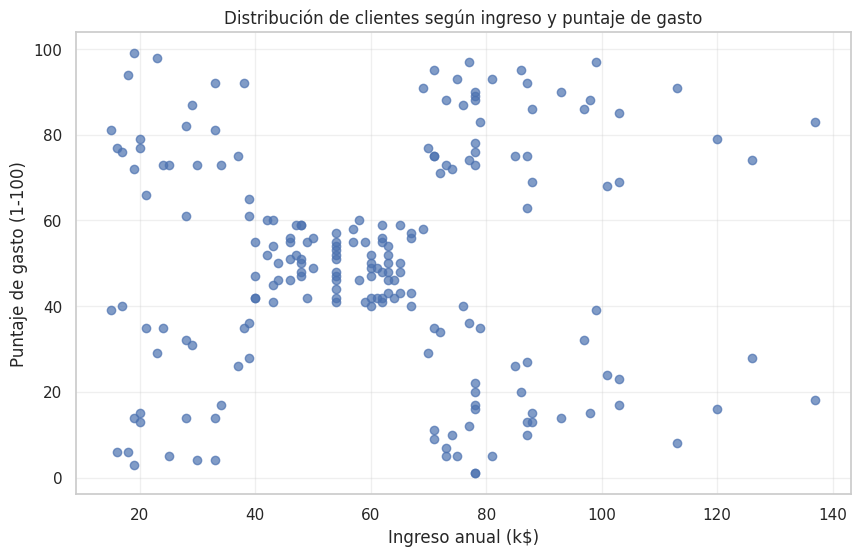

In [16]:
# ==========================================
# GRÁFICO INICIAL DE DISPERSIÓN
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    X_clientes["Annual Income (k$)"],
    X_clientes["Spending Score (1-100)"],
    alpha=0.7
)

plt.title("Distribución de clientes según ingreso y puntaje de gasto")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto (1-100)")

plt.grid(True, alpha=0.3)
plt.show()

### Hipótesis visual inicial

Al observar el gráfico de dispersión de las variables Annual Income y Spending Score, se identifican aproximadamente cinco agrupaciones de clientes.

Las concentraciones visuales corresponden a los siguientes perfiles:

1. Clientes con ingresos bajos y puntaje de gasto bajo.
2. Clientes con ingresos bajos y puntaje de gasto alto.
3. Clientes con ingresos medios y puntaje de gasto medio.
4. Clientes con ingresos altos y puntaje de gasto bajo.
5. Clientes con ingresos altos y puntaje de gasto alto.

Por lo tanto, se plantea inicialmente la hipótesis de cinco posibles segmentos. Esta observación se utilizará como referencia para comparar posteriormente los resultados obtenidos mediante K-means.

Sin embargo, la existencia y calidad de estos grupos deberá comprobarse mediante métricas de evaluación, estabilidad y análisis de los perfiles obtenidos.

In [17]:
# ==========================================
# ESTANDARIZACIÓN DE VARIABLES
# ==========================================

from sklearn.preprocessing import StandardScaler

# Crear el escalador
scaler = StandardScaler()

# Ajustar y transformar las variables
X_scaled = scaler.fit_transform(X_clientes)

# Convertir a DataFrame conservando los nombres
X_estandarizado = pd.DataFrame(
    X_scaled,
    columns=variables,
    index=X_clientes.index
)

print("Datos originales:")
display(X_clientes.head())

print("\nDatos estandarizados:")
display(X_estandarizado.head())

print("\nMedia de las variables estandarizadas:")
display(X_estandarizado.mean())

print("\nDesviación estándar:")
display(X_estandarizado.std(ddof=0))

Datos originales:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Datos estandarizados:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Media de las variables estandarizadas:


,0
Annual Income (k$),-2.131628e-16
Spending Score (1-100),-1.465494e-16



Desviación estándar:


,0
Annual Income (k$),1.0
Spending Score (1-100),1.0


### 3. Preparación y estandarización de variables

Las variables seleccionadas presentan los siguientes rangos:

- Annual Income (k$): mínimo 15 y máximo 137.
- Spending Score (1-100): mínimo 1 y máximo 99.

Se aplicó StandardScaler para estandarizar ambas variables, obteniendo medias cercanas a cero y desviaciones estándar iguales a uno.

Se decidió trabajar inicialmente con los datos estandarizados para evitar que las diferencias de escala influyan desproporcionadamente en el cálculo de las distancias euclidianas.

Se conservaron también los datos originales para comparar posteriormente los resultados de K-means con y sin estandarización y facilitar la interpretación de los segmentos en sus unidades originales.

In [18]:
# ==========================================
# EVALUACIÓN DE K-MEANS: K DE 2 A 10
# ==========================================

inercias = []
siluetas = []
valores_k = range(2, 11)

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_estandarizado)

    inercias.append(modelo.inertia_)

    silueta = silhouette_score(
        X_estandarizado,
        etiquetas
    )

    siluetas.append(silueta)

    print(
        f"K={k} | "
        f"Inercia={modelo.inertia_:.2f} | "
        f"Silueta={silueta:.4f}"
    )

print("\nEvaluación completada correctamente.")

K=2 | Inercia=269.69 | Silueta=0.3213
K=3 | Inercia=157.70 | Silueta=0.4666
K=4 | Inercia=108.92 | Silueta=0.4939
K=5 | Inercia=65.57 | Silueta=0.5547
K=6 | Inercia=55.06 | Silueta=0.5399
K=7 | Inercia=44.86 | Silueta=0.5281
K=8 | Inercia=37.23 | Silueta=0.4552
K=9 | Inercia=32.39 | Silueta=0.4571
K=10 | Inercia=29.98 | Silueta=0.4432

Evaluación completada correctamente.


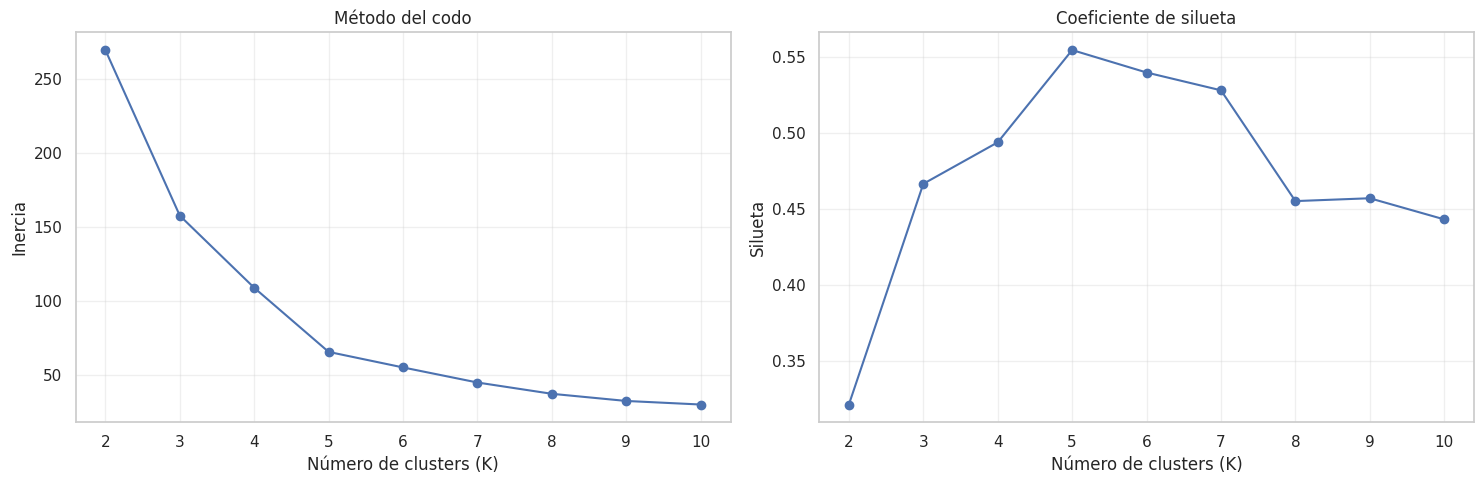

In [19]:
# ==========================================
# GRÁFICOS DE EVALUACIÓN DE K-MEANS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico del método del codo
axes[0].plot(
    list(valores_k),
    inercias,
    marker="o"
)

axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (K)")
axes[0].set_ylabel("Inercia")
axes[0].set_xticks(list(valores_k))
axes[0].grid(True, alpha=0.3)

# Gráfico de silueta
axes[1].plot(
    list(valores_k),
    siluetas,
    marker="o"
)

axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("Número de clusters (K)")
axes[1].set_ylabel("Silueta")
axes[1].set_xticks(list(valores_k))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4. Evaluación del número de clusters

Se evaluaron diferentes valores de K, desde 2 hasta 10, utilizando las métricas de inercia y coeficiente de silueta.

Se observó que la inercia disminuye progresivamente al aumentar el número de clusters, debido a que los grupos se vuelven más pequeños y sus observaciones quedan más cerca de sus centroides. Por esta razón, no es suficiente utilizar únicamente esta métrica para seleccionar K.

El método del codo mostró un cambio importante en la pendiente alrededor de K=5. Por otra parte, el coeficiente de silueta alcanzó su valor máximo en K=5, con un resultado de 0.5547.

Ambas evidencias respaldan inicialmente la selección de cinco clusters, coincidiendo también con la hipótesis visual planteada al comienzo del ejercicio.

Sin embargo, la decisión definitiva se complementará con pruebas de estabilidad y utilidad de los segmentos.

In [20]:
# ==========================================
# ANÁLISIS DE ESTABILIDAD DE K-MEANS
# ==========================================

# Modelo de referencia
modelo_base = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

etiquetas_base = modelo_base.fit_predict(X_estandarizado)

# Comparar con diferentes semillas
semillas = [10, 21, 42, 100, 123, 2026]

resultados_estabilidad = []

for semilla in semillas:

    modelo = KMeans(
        n_clusters=5,
        random_state=semilla,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_estandarizado)

    ari = adjusted_rand_score(
        etiquetas_base,
        etiquetas
    )

    resultados_estabilidad.append({
        "Semilla": semilla,
        "ARI": ari,
        "Inercia": modelo.inertia_
    })

df_estabilidad = pd.DataFrame(resultados_estabilidad)

display(df_estabilidad)

print(
    "\nARI promedio:",
    round(df_estabilidad["ARI"].mean(), 4)
)

,Semilla,ARI,Inercia
0,10,1.0,65.568408
1,21,1.0,65.568408
2,42,1.0,65.568408
3,100,1.0,65.568408
4,123,1.0,65.568408
5,2026,1.0,65.568408



ARI promedio: 1.0


### Análisis de estabilidad de K-Means

Se evaluó la estabilidad del algoritmo K-Means utilizando cinco grupos (K=5) y seis semillas aleatorias diferentes.

Los resultados mostraron un ARI de 1.0 en todas las ejecuciones, con un promedio de 1.0. Además, la inercia se mantuvo constante en 65.568408.

Esto indica que el algoritmo generó agrupamientos idénticos entre las distintas ejecuciones, demostrando una excelente estabilidad. Por lo tanto, K=5 se mantiene como una alternativa confiable para continuar con el análisis de segmentación de clientes.

In [21]:
# ==========================================
# COMPARACIÓN: DATOS ESTANDARIZADOS VS ORIGINALES
# ==========================================

# K-Means con datos estandarizados
modelo_std = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

etiquetas_std = modelo_std.fit_predict(X_estandarizado)


# K-Means con datos originales
modelo_original = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

etiquetas_original = modelo_original.fit_predict(X_clientes)


# Comparar agrupamientos mediante ARI
ari_comparacion = adjusted_rand_score(
    etiquetas_std,
    etiquetas_original
)

print("ARI entre datos estandarizados y originales:",
      round(ari_comparacion, 4))

print("\nInercia con datos estandarizados:",
      round(modelo_std.inertia_, 4))

print("Inercia con datos originales:",
      round(modelo_original.inertia_, 4))

ARI entre datos estandarizados y originales: 1.0

Inercia con datos estandarizados: 65.5684
Inercia con datos originales: 44448.4554


### Comparación entre datos estandarizados y originales

Se compararon dos modelos K-Means con cinco grupos: uno utilizando variables estandarizadas y otro utilizando las variables originales.

El índice ARI obtenido fue 1.0, lo que indica que ambos modelos generaron exactamente la misma distribución de clientes en los cinco grupos.

La inercia fue de 65.5684 para los datos estandarizados y 44448.4554 para los datos originales. Estos valores no son directamente comparables porque se encuentran en escalas diferentes.

En este caso, la estandarización no modificó la asignación de los clientes, aunque permite trabajar con variables expresadas en escalas comparables.

In [22]:
# ==========================================
# MODELO K-MEANS DEFINITIVO
# ==========================================

modelo_final = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Asignar grupos a cada cliente
df_clientes["Cluster"] = modelo_final.fit_predict(X_estandarizado)

# Mostrar los primeros registros
display(df_clientes.head(10))

# Contar clientes por grupo
print("\nCantidad de clientes por grupo:")
display(df_clientes["Cluster"].value_counts().sort_index())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2



Cantidad de clientes por grupo:


,count
Cluster,
0,81
1,39
2,22
3,35
4,23


In [23]:
# ==========================================
# PERFIL DE LOS CLIENTES POR CLUSTER
# ==========================================

perfil_clusters = df_clientes.groupby("Cluster").agg(
    Cantidad=("CustomerID", "count"),
    Edad_Promedio=("Age", "mean"),
    Ingreso_Promedio=("Annual Income (k$)", "mean"),
    Gasto_Promedio=("Spending Score (1-100)", "mean"),
    Ingreso_Mediana=("Annual Income (k$)", "median"),
    Gasto_Mediana=("Spending Score (1-100)", "median")
).round(2)

display(perfil_clusters)

,Cantidad,Edad_Promedio,Ingreso_Promedio,Gasto_Promedio,Ingreso_Mediana,Gasto_Mediana
Cluster,,,,,,
0,81,42.72,55.30,49.52,54.0,50.0
1,39,32.69,86.54,82.13,79.0,83.0
2,22,25.27,25.73,79.36,24.5,77.0
3,35,41.11,88.20,17.11,85.0,16.0
4,23,45.22,26.30,20.91,25.0,17.0


### Interpretación y caracterización de los segmentos

A partir de los promedios de ingresos y puntuación de gasto, se identificaron cinco perfiles de clientes:

- **Cluster 0 – Clientes intermedios:** representan el grupo más numeroso, con 81 clientes. Presentan ingresos y gastos cercanos a los valores medios del conjunto.
- **Cluster 1 – Clientes de alto valor:** compuesto por 39 clientes, con ingresos altos y una puntuación de gasto elevada.
- **Cluster 2 – Clientes de bajo ingreso y alto gasto:** reúne 22 clientes que, pese a tener ingresos bajos, presentan una alta puntuación de gasto.
- **Cluster 3 – Clientes de alto ingreso y bajo gasto:** formado por 35 clientes con ingresos elevados, pero una puntuación de gasto reducida.
- **Cluster 4 – Clientes de bajo ingreso y bajo gasto:** compuesto por 23 clientes, con ingresos y puntuaciones de gasto bajos.

Esta segmentación permite reconocer distintos comportamientos de consumo y plantear estrategias comerciales diferenciadas. Los nombres asignados son interpretaciones descriptivas basadas en los promedios observados.

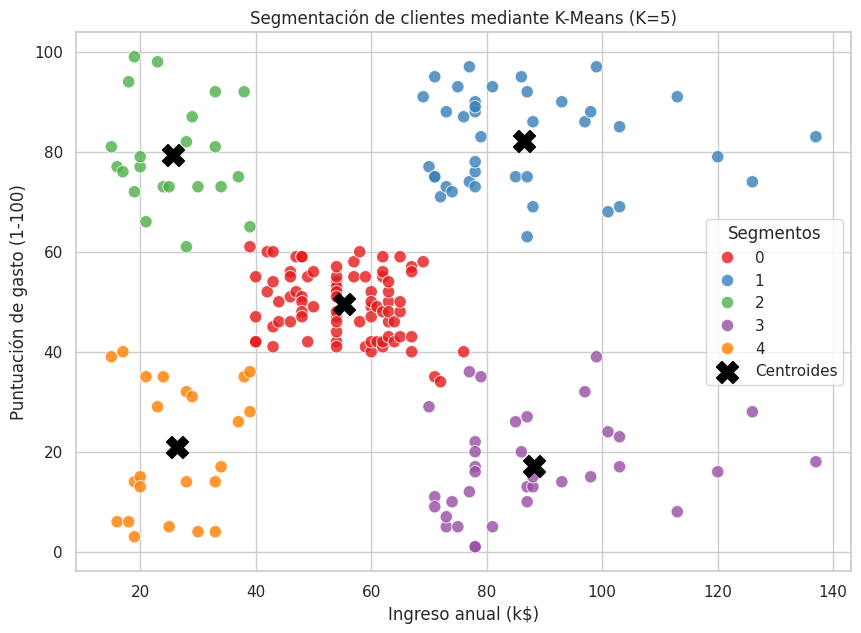

In [24]:
# ==========================================
# VISUALIZACIÓN DE LOS CLUSTERS Y CENTROIDES
# ==========================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_clientes,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=80,
    alpha=0.8
)

# Centroides en escala original
centroides_originales = scaler.inverse_transform(
    modelo_final.cluster_centers_
)

plt.scatter(
    centroides_originales[:, 0],
    centroides_originales[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroides"
)

plt.title("Segmentación de clientes mediante K-Means (K=5)")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntuación de gasto (1-100)")
plt.legend(title="Segmentos")
plt.show()

### Visualización e interpretación de la segmentación final

La gráfica representa el resultado de aplicar el algoritmo K-Means con K=5, utilizando las variables de ingreso anual y puntuación de gasto de los clientes.

Cada color representa un clúster diferente y las marcas X negras corresponden a los centroides, que representan el centro de cada agrupación.

Se identifican los siguientes segmentos:

- **Cluster 0:** clientes con ingresos y gastos medios. Es el grupo más numeroso, con 81 clientes.
- **Cluster 1:** clientes con ingresos altos y puntuaciones de gasto elevadas. Representa un segmento de alto valor comercial.
- **Cluster 2:** clientes con ingresos bajos y puntuaciones de gasto elevadas.
- **Cluster 3:** clientes con ingresos altos y puntuaciones de gasto reducidas.
- **Cluster 4:** clientes con ingresos bajos y puntuaciones de gasto reducidas.

Los centroides permiten identificar la posición promedio de cada segmento en el espacio de variables. Esta visualización facilita la comparación de los comportamientos de consumo y permite proponer estrategias comerciales diferenciadas.

En conclusión, K-Means permitió identificar cinco perfiles de clientes con características distintas a partir de sus ingresos y puntuaciones de gasto.

### Propuestas de estrategias comerciales por segmento

A partir de los cinco grupos identificados, se proponen las siguientes estrategias:

1. **Cluster 0 – Clientes intermedios:** implementar promociones generales, programas de fidelización y recomendaciones personalizadas para incentivar el consumo.
2. **Cluster 1 – Clientes de alto valor:** ofrecer beneficios exclusivos, recompensas, atención preferencial y programas VIP para mantener su fidelidad.
3. **Cluster 2 – Clientes de bajo ingreso y alto gasto:** desarrollar campañas de fidelización, descuentos por volumen y promociones atractivas.
4. **Cluster 3 – Clientes de alto ingreso y bajo gasto:** aplicar campañas personalizadas, recomendaciones de productos y promociones especiales para incentivar las compras.
5. **Cluster 4 – Clientes de bajo ingreso y bajo gasto:** ofrecer promociones económicas, descuentos y productos accesibles para estimular el consumo.

Estas estrategias son propuestas basadas en los perfiles obtenidos mediante el modelo y podrían validarse posteriormente con información real de ventas y comportamiento de compra.

## Conclusiones del ejercicio 1: Segmentación de clientes con K-Means

Durante este ejercicio se aplicó el algoritmo de aprendizaje no supervisado K-Means sobre el conjunto de datos Mall Customers, compuesto por 200 clientes.

Inicialmente, se realizó una exploración de los datos, verificando sus dimensiones, valores faltantes y registros duplicados. Posteriormente, se seleccionaron las variables Annual Income (k$) y Spending Score (1-100), excluyendo el identificador CustomerID y la variable categórica Gender.

Se estandarizaron las variables y se evaluaron distintos valores de K mediante el método del codo y el coeficiente de silueta. Se seleccionó K=5, debido a que obtuvo el mayor coeficiente de silueta (0.5547) y presentó un cambio relevante en la curva de inercia.

También se comprobó la estabilidad del modelo mediante seis semillas aleatorias, obteniendo un ARI promedio de 1.0. La comparación entre los datos originales y estandarizados también presentó un ARI de 1.0.

Finalmente, se identificaron cinco segmentos de clientes con características diferenciadas según sus ingresos y puntuaciones de gasto. Estos resultados permiten comprender mejor los patrones de comportamiento de los clientes y proponer estrategias comerciales específicas para cada grupo.

En conclusión, K-Means permitió realizar una segmentación clara y estable, demostrando la utilidad de las técnicas de aprendizaje no supervisado para analizar y descubrir patrones en conjuntos de datos.

In [25]:
from google.colab import files

archivos = files.upload()

Saving Country-data.csv to Country-data.csv


In [26]:
import pandas as pd

df_paises = pd.read_csv("Country-data.csv")

print("Dimensiones del conjunto de datos:")
print(df_paises.shape)

print("\nPrimeros registros:")
display(df_paises.head())

print("\nInformación general:")
df_paises.info()

Dimensiones del conjunto de datos:
(167, 10)

Primeros registros:


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


In [27]:
# ==========================================
# REVISIÓN DE CALIDAD DE LOS DATOS
# ==========================================

print("Valores faltantes por columna:")
display(df_paises.isnull().sum())

print("\nCantidad de filas duplicadas:")
print(df_paises.duplicated().sum())

print("\n¿Chile está presente en el dataset?")
print(df_paises["country"].str.lower().eq("chile").any())

print("\nRegistro de Chile:")
display(
    df_paises[
        df_paises["country"].str.lower() == "chile"
    ]
)

Valores faltantes por columna:


,0
country,0
child_mort,0
exports,0
health,0
imports,0
income,0
inflation,0
life_expec,0
total_fer,0
gdpp,0



Cantidad de filas duplicadas:
0

¿Chile está presente en el dataset?
True

Registro de Chile:


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
33,Chile,8.7,37.7,7.96,31.3,19400,8.96,79.1,1.88,12900


In [28]:
# ==========================================
# SELECCIÓN DE 30 PAÍSES
# ==========================================

# Separar Chile del resto de los países
chile = df_paises[
    df_paises["country"] == "Chile"
]

otros_paises = df_paises[
    df_paises["country"] != "Chile"
]

# Seleccionar 29 países aleatoriamente
muestra_otros = otros_paises.sample(
    n=29,
    random_state=42
)

# Unir los 29 países con Chile
df_muestra = pd.concat(
    [chile, muestra_otros],
    ignore_index=True
)

# Revisar la muestra
print("Cantidad de países seleccionados:", len(df_muestra))

display(df_muestra[["country"]])

print("\n¿Chile está incluido?")
print("Chile" in df_muestra["country"].values)

Cantidad de países seleccionados: 30


,country
0,Chile
1,"Micronesia, Fed. Sts."
2,South Africa
3,Kazakhstan
4,Georgia
5,Malta
6,Canada
7,Morocco
8,Kyrgyz Republic
9,Venezuela



¿Chile está incluido?
True


In [29]:
# ==========================================
# PREPARACIÓN DE VARIABLES
# ==========================================

# Guardar los nombres de los países
nombres_paises = df_muestra["country"].copy()

# Seleccionar solamente variables numéricas
variables_paises = [
    "child_mort",
    "exports",
    "health",
    "imports",
    "income",
    "inflation",
    "life_expec",
    "total_fer",
    "gdpp"
]

X_paises = df_muestra[variables_paises].copy()

# Revisar dimensiones y primeras filas
print("Dimensiones de la matriz:", X_paises.shape)

display(X_paises.head())

print("\nEstadísticas descriptivas:")
display(X_paises.describe().round(2))

Dimensiones de la matriz: (30, 9)


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,8.7,37.7,7.96,31.3,19400,8.96,79.1,1.88,12900
1,40.0,23.5,14.20,81.0,3340,3.80,65.4,3.46,2860
2,53.7,28.6,8.94,27.4,12000,6.35,54.3,2.59,7280
3,21.5,44.2,4.29,29.9,20100,19.50,68.4,2.60,9070
4,16.5,35.0,10.10,52.8,6730,8.55,72.8,1.92,2960



Estadísticas descriptivas:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,30.00,30.00,30.00,30.00,30.00,30.00,30.00,30.00,30.00
mean,33.18,46.67,7.28,54.62,15461.60,7.46,71.05,2.57,12017.90
std,37.96,39.49,2.92,36.10,16570.64,9.05,8.56,1.17,15912.91
min,2.60,9.58,3.52,13.60,888.00,-1.90,47.50,1.15,399.00
25%,9.22,24.98,4.98,31.08,3482.50,1.91,68.32,1.86,1717.50
50%,20.15,38.45,6.03,46.25,7940.00,5.73,71.50,2.36,4510.00
75%,42.03,52.95,9.28,69.00,19925.00,9.60,76.97,2.70,13350.00
max,160.00,200.00,14.20,174.00,72100.00,45.90,82.80,5.71,47400.00


In [30]:
# ==========================================
# ESTANDARIZACIÓN DE LOS INDICADORES
# ==========================================

scaler_paises = StandardScaler()

X_paises_scaled = scaler_paises.fit_transform(X_paises)

# Convertir nuevamente a DataFrame
X_paises_estandarizado = pd.DataFrame(
    X_paises_scaled,
    columns=variables_paises,
    index=X_paises.index
)

print("Primeros registros estandarizados:")
display(X_paises_estandarizado.head())

print("\nPromedios de las variables:")
display(X_paises_estandarizado.mean().round(4))

print("\nDesviaciones estándar:")
display(X_paises_estandarizado.std(ddof=0).round(4))

Primeros registros estandarizados:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,-0.655830,-0.230925,0.236147,-0.657065,0.241736,0.168844,0.956493,-0.598856,0.056381
1,0.182711,-0.596654,2.410609,0.743084,-0.744016,-0.410820,-0.671327,0.770453,-0.585340
2,0.549740,-0.465301,0.577650,-0.766936,-0.212471,-0.124358,-1.990218,0.016466,-0.302829
3,-0.312912,-0.063513,-1.042743,-0.696506,0.284702,1.352885,-0.314870,0.025133,-0.188419
4,-0.446864,-0.300465,0.981876,-0.051367,-0.535940,0.122785,0.207933,-0.564190,-0.578948



Promedios de las variables:


,0
child_mort,0.0
exports,0.0
health,-0.0
imports,-0.0
income,-0.0
inflation,-0.0
life_expec,0.0
total_fer,0.0
gdpp,-0.0



Desviaciones estándar:


,0
child_mort,1.0
exports,1.0
health,1.0
imports,1.0
income,1.0
inflation,1.0
life_expec,1.0
total_fer,1.0
gdpp,1.0


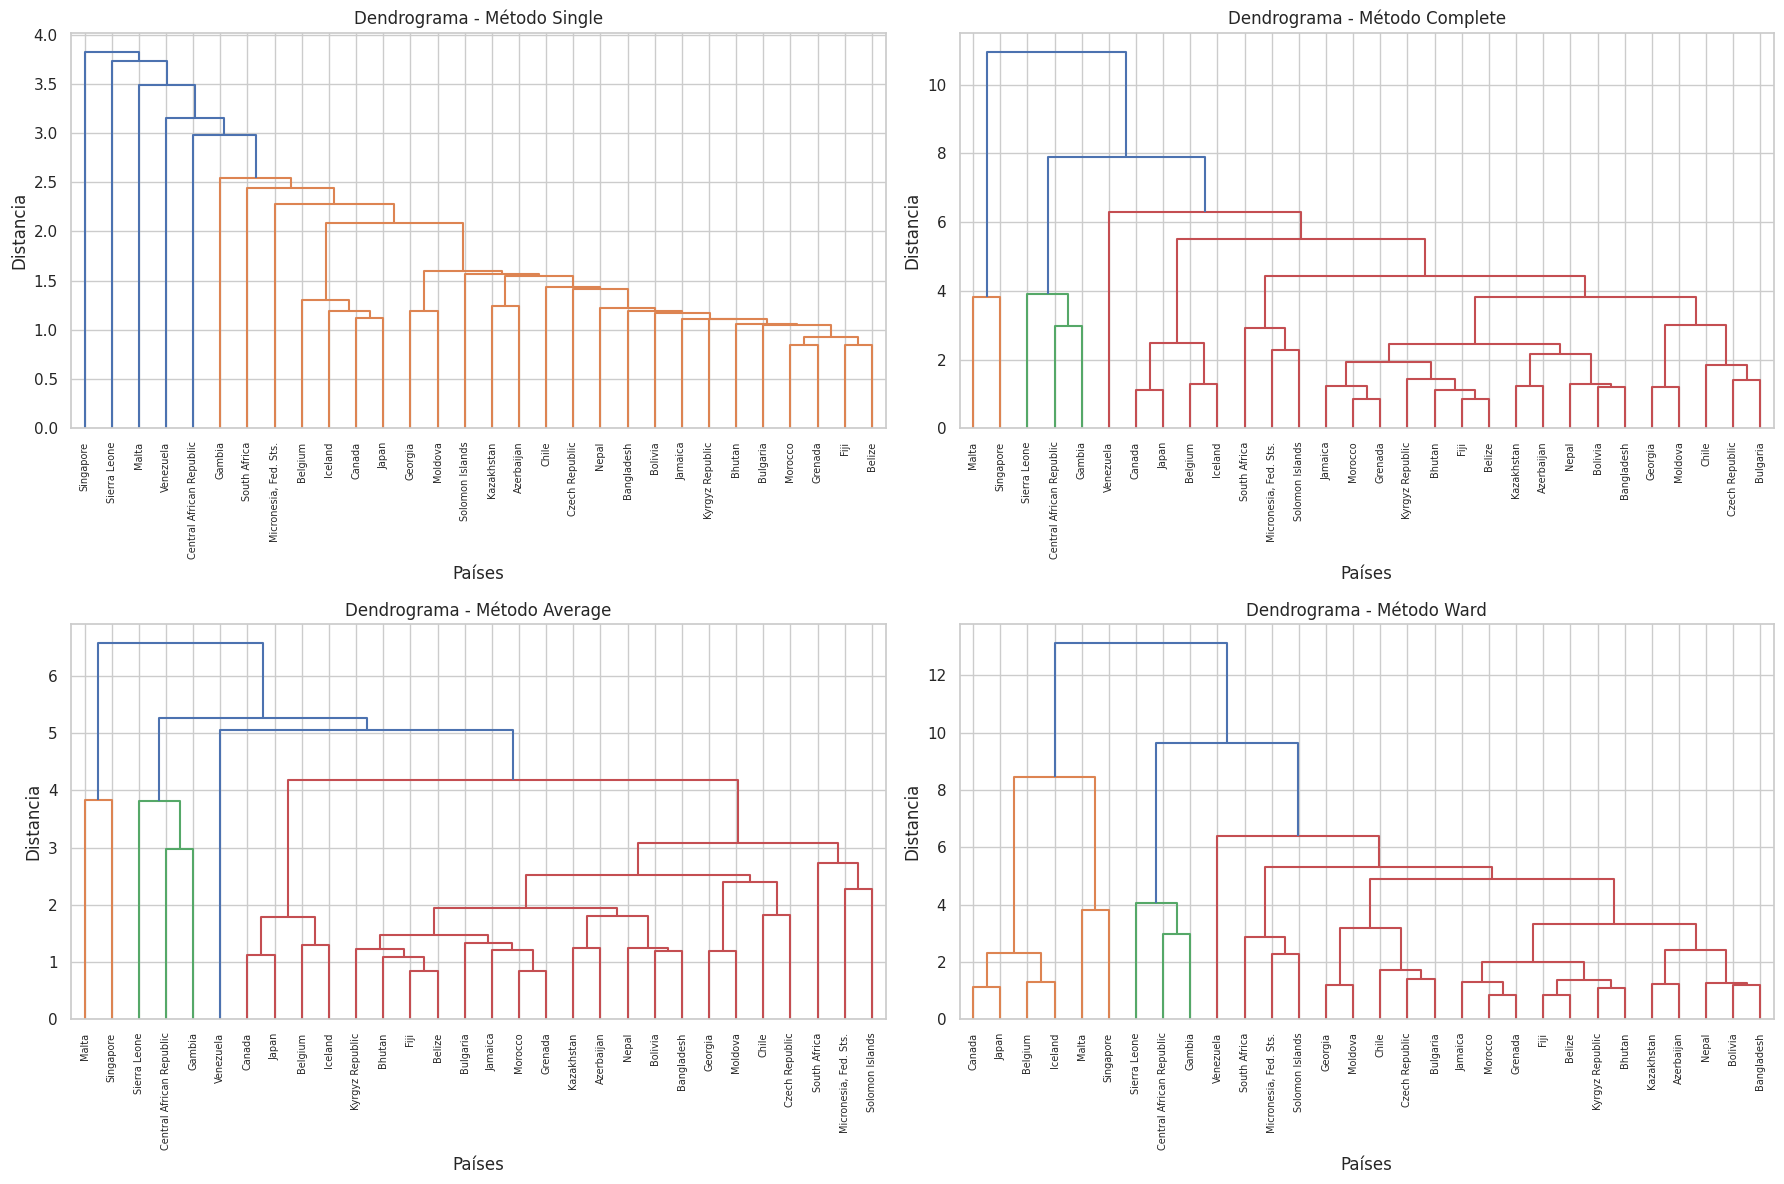

In [31]:
# ==========================================
# CLUSTERING JERÁRQUICO: CUATRO MÉTODOS
# ==========================================

metodos = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for metodo, ax in zip(metodos, axes.flatten()):

    Z = linkage(
        X_paises_estandarizado,
        method=metodo,
        metric="euclidean"
    )

    dendrogram(
        Z,
        labels=nombres_paises.values,
        leaf_rotation=90,
        leaf_font_size=7,
        ax=ax
    )

    ax.set_title(f"Dendrograma - Método {metodo.capitalize()}")
    ax.set_xlabel("Países")
    ax.set_ylabel("Distancia")

plt.tight_layout()
plt.show()

In [32]:
enlaces = {}

for metodo in ["single", "complete", "average", "ward"]:
    enlaces[metodo] = linkage(
        X_paises_estandarizado,
        method=metodo,
        metric="euclidean"
    )

print("Matrices de enlace generadas:")
for metodo, Z in enlaces.items():
    print(f"{metodo}: {Z.shape}")

Matrices de enlace generadas:
single: (29, 4)
complete: (29, 4)
average: (29, 4)
ward: (29, 4)


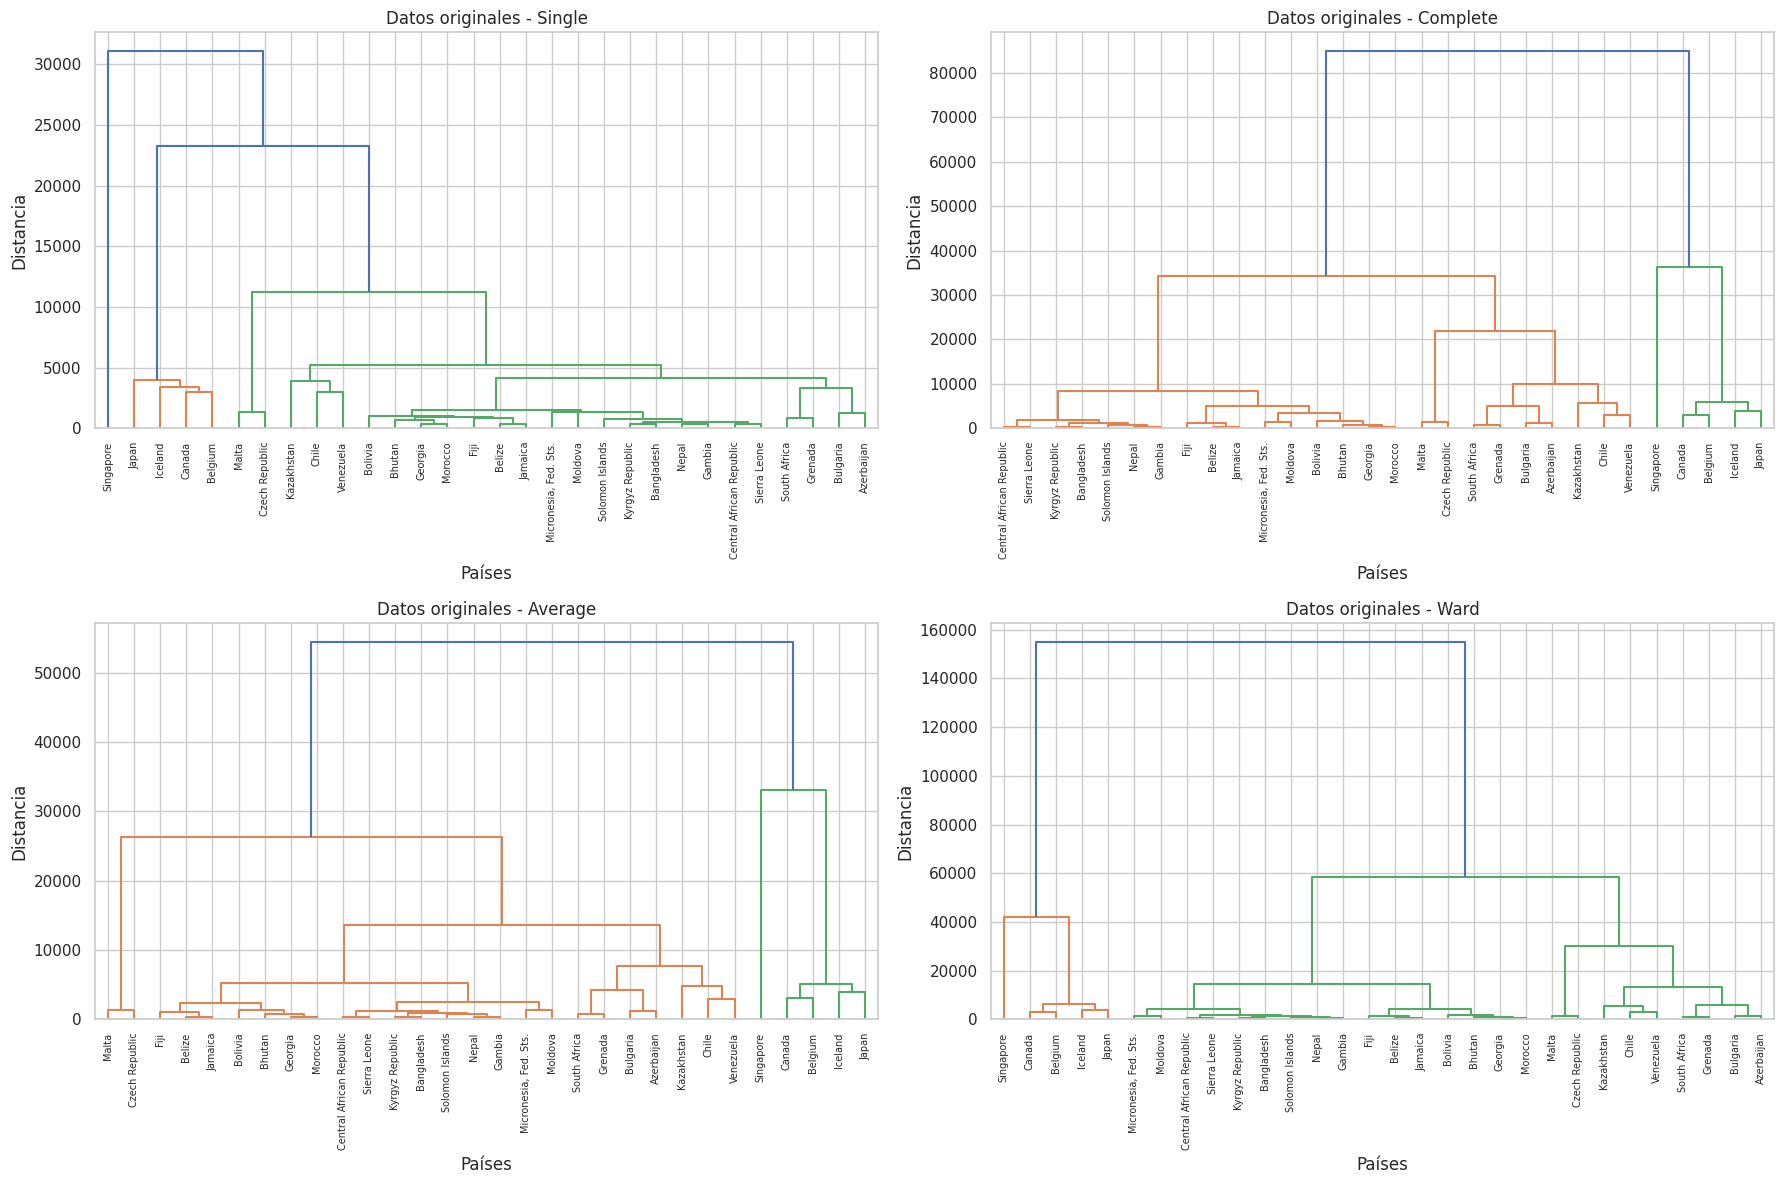

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for metodo, ax in zip(
    ["single", "complete", "average", "ward"],
    axes.flatten()
):
    Z_original = linkage(
        X_paises,
        method=metodo,
        metric="euclidean"
    )

    dendrogram(
        Z_original,
        labels=nombres_paises.values,
        leaf_rotation=90,
        leaf_font_size=7,
        ax=ax
    )

    ax.set_title(f"Datos originales - {metodo.capitalize()}")
    ax.set_xlabel("Países")
    ax.set_ylabel("Distancia")

plt.tight_layout()
plt.show()

In [34]:
print("Comparación de distancias máximas:\n")

for metodo in ["single", "complete", "average", "ward"]:
    Z_estandarizado = enlaces[metodo]

    Z_original = linkage(
        X_paises,
        method=metodo,
        metric="euclidean"
    )

    print(f"Método: {metodo}")
    print(f"  Datos estandarizados: {Z_estandarizado[:, 2].max():.4f}")
    print(f"  Datos originales:     {Z_original[:, 2].max():.4f}")
    print()

Comparación de distancias máximas:

Método: single
  Datos estandarizados: 3.8280
  Datos originales:     31078.3719

Método: complete
  Datos estandarizados: 10.9610
  Datos originales:     84861.1835

Método: average
  Datos estandarizados: 6.5841
  Datos originales:     54420.7921

Método: ward
  Datos estandarizados: 13.1379
  Datos originales:     154901.7014



In [35]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score

Z_ward = enlaces["ward"]

resultados_ward = []

for k in [2, 3, 4, 5]:
    etiquetas = fcluster(
        Z_ward,
        t=k,
        criterion="maxclust"
    )

    silueta = silhouette_score(
        X_paises_estandarizado,
        etiquetas
    )

    resultados_ward.append({
        "Clusters": k,
        "Silueta": silueta,
        "Grupos obtenidos": len(set(etiquetas))
    })

df_resultados_ward = pd.DataFrame(resultados_ward)

display(df_resultados_ward)

,Clusters,Silueta,Grupos obtenidos
0,2,0.386372,2
1,3,0.370161,3
2,4,0.379595,4
3,5,0.382523,5


In [36]:
etiquetas_ward = fcluster(
    enlaces["ward"],
    t=2,
    criterion="maxclust"
)

df_resultado_paises = df_muestra.copy()
df_resultado_paises["Cluster"] = etiquetas_ward

print("Cantidad de países por clúster:")
display(df_resultado_paises["Cluster"].value_counts().sort_index())

print("\nPaíses asignados:")
display(
    df_resultado_paises[["country", "Cluster"]]
    .sort_values("Cluster")
    .reset_index(drop=True)
)

Cantidad de países por clúster:


,count
Cluster,
1,6
2,24



Países asignados:


,country,Cluster
0,Canada,1
1,Malta,1
2,Belgium,1
3,Iceland,1
4,Singapore,1
5,Japan,1
6,Kazakhstan,2
7,South Africa,2
8,Morocco,2
9,Georgia,2


In [37]:
perfil_paises = df_resultado_paises.groupby("Cluster")[
    variables_paises
].mean().round(2)

print("Perfil promedio de los clústeres:")
display(perfil_paises)

Perfil promedio de los clústeres:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
Cluster,,,,,,,,,
1,4.25,87.82,8.92,81.77,42800.0,2.02,81.52,1.60,40983.33
2,40.41,36.38,6.87,47.84,8627.0,8.82,68.43,2.81,4776.54


In [38]:
chile_comparacion = df_resultado_paises[
    df_resultado_paises["country"] == "Chile"
][variables_paises].T

chile_comparacion.columns = ["Chile"]

chile_comparacion["Promedio_Cluster_2"] = (
    perfil_paises.loc[2]
)

chile_comparacion["Diferencia"] = (
    chile_comparacion["Chile"] -
    chile_comparacion["Promedio_Cluster_2"]
)

display(chile_comparacion.round(2))

,Chile,Promedio_Cluster_2,Diferencia
child_mort,8.70,40.41,-31.71
exports,37.70,36.38,1.32
health,7.96,6.87,1.09
imports,31.30,47.84,-16.54
income,19400.00,8627.00,10773.00
inflation,8.96,8.82,0.14
life_expec,79.10,68.43,10.67
total_fer,1.88,2.81,-0.93
gdpp,12900.00,4776.54,8123.46


In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

modelo_kmeans_paises = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

etiquetas_kmeans = modelo_kmeans_paises.fit_predict(
    X_paises_estandarizado
)

ari_paises = adjusted_rand_score(
    etiquetas_ward,
    etiquetas_kmeans
)

print("Comparación Ward vs. K-Means")
print("--------------------------------")
print(f"ARI: {ari_paises:.4f}")

print("\nTabla de comparación:")
display(
    pd.crosstab(
        etiquetas_ward,
        etiquetas_kmeans,
        rownames=["Ward"],
        colnames=["K-Means"]
    )
)

Comparación Ward vs. K-Means
--------------------------------
ARI: 0.8538

Tabla de comparación:


K-Means,0,1
Ward,,
1,0,6
2,23,1


In [40]:
print("RESUMEN DEL CLUSTERING JERÁRQUICO")
print("=" * 45)

print("\nMétodo utilizado: Ward")
print("Cantidad de países:", len(df_muestra))
print("Cantidad de variables:", len(variables_paises))
print("Cantidad de clústeres seleccionados: 2")

print("\nÍndice Silhouette:")
print(df_resultados_ward)

print("\nDistribución de países:")
print(df_resultado_paises["Cluster"].value_counts().sort_index())

print("\nPaís asignado a Chile:")
print(
    df_resultado_paises.loc[
        df_resultado_paises["country"] == "Chile",
        ["country", "Cluster"]
    ]
)

print("\nConcordancia Ward vs. K-Means:")
print(f"ARI: {ari_paises:.4f}")

RESUMEN DEL CLUSTERING JERÁRQUICO

Método utilizado: Ward
Cantidad de países: 30
Cantidad de variables: 9
Cantidad de clústeres seleccionados: 2

Índice Silhouette:
   Clusters   Silueta  Grupos obtenidos
0         2  0.386372                 2
1         3  0.370161                 3
2         4  0.379595                 4
3         5  0.382523                 5

Distribución de países:
Cluster
1     6
2    24
Name: count, dtype: int64

País asignado a Chile:
  country  Cluster
0   Chile        2

Concordancia Ward vs. K-Means:
ARI: 0.8538


## Conclusiones del Ejercicio 2: Clustering Jerárquico

Para este ejercicio se aplicó clustering jerárquico sobre una muestra de 30 países, considerando nueve indicadores relacionados con aspectos económicos, sociales y de salud.

Inicialmente, se realizó una exploración y limpieza de los datos, verificando que no existieran valores nulos ni registros duplicados. Posteriormente, se seleccionaron las variables numéricas y se aplicó estandarización mediante StandardScaler para evitar que las diferencias de escala afectaran el cálculo de distancias.

Se compararon cuatro métodos de agrupamiento: Single, Complete, Average y Ward. También se evaluó el efecto de utilizar datos originales y estandarizados, observando diferencias importantes en las distancias máximas.

Se seleccionó el método Ward y se evaluaron agrupaciones de 2, 3, 4 y 5 clústeres mediante el índice Silhouette. La mejor puntuación correspondió a dos clústeres, con un valor de **0,386372**, por lo que se eligió esta configuración.

Los resultados identificaron dos grupos:

- **Clúster 1:** 6 países con mayores ingresos, mayor PIB per cápita, mayor esperanza de vida y menor mortalidad infantil.
- **Clúster 2:** 24 países con menores ingresos promedio, menor PIB per cápita, menor esperanza de vida y mayor mortalidad infantil.

Chile quedó clasificado en el clúster 2. Sin embargo, al comparar sus indicadores con el promedio de ese grupo, se observó que presenta condiciones más favorables en aspectos como ingresos, PIB per cápita, esperanza de vida y mortalidad infantil.

Finalmente, se comparó el resultado de Ward con K-Means utilizando dos grupos. Se obtuvo un índice ARI de **0,8538**, lo que demuestra una alta concordancia entre ambos algoritmos.

En conclusión, el clustering jerárquico permitió identificar dos agrupaciones de países con características económicas y sociales diferenciadas. La estandarización y la comparación mediante métricas de evaluación fueron fundamentales para obtener e interpretar los resultados.